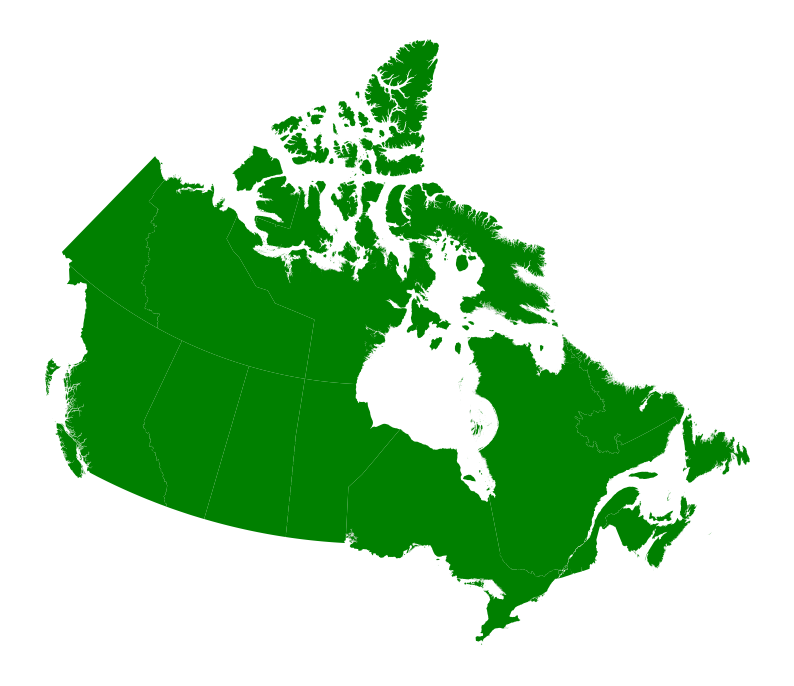

In [6]:
import geopandas as gpd
import matplotlib.pyplot as plt

# Path to your shapefile (make sure all required files are in the same directory)
shapefile_path = '/home/emh_2024/Documents/message-ix/output/shapefile/lpr_000b16a_e.shp'

# Load the shapefile using geopandas
gdf = gpd.read_file(shapefile_path)

# Create a plot with light green color filling the geometries
ax = gdf.plot(figsize=(10, 10), color='green', edgecolor='none')

# Remove axis labels and ticks
ax.set_axis_off()

# Show the plot
plt.show()

In [14]:
import geopandas as gpd
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.offsetbox import AnchoredOffsetbox, AuxTransformBox
from matplotlib.transforms import Affine2D
from matplotlib import cm


# Load the CSV file with electricity generation data
csv_file_path = '/home/emh_2024/Documents/message-ix/output/output_dataframes/msgresults_new.csv'
df = pd.read_csv(csv_file_path)

# Filter the data for electricity generation values
electricity_df = df[df['variable'].str.contains('Electricity generation')]

# Align the region names by removing spaces in the CSV file region column
electricity_df['region'] = electricity_df['region'].str.replace(' ', '')

# Align with the shapefile's province names (PRENAME)
gdf['PRENAME'] = gdf['PRENAME'].str.replace(' ', '')

# Define the year to filter by (e.g., 2020 or 2050)
year_to_filter = 2020  # Change to 2050 as needed

# Filter the electricity data for the chosen year
filtered_electricity_df = electricity_df[electricity_df['time'] == year_to_filter]

# Merge the electricity generation data with the GeoDataFrame
gdf = gdf.merge(filtered_electricity_df[['region', 'value']], left_on='PRENAME', right_on='region', how='left')

# Create a colormap for value differences
norm = plt.Normalize(vmin=gdf['value'].min(), vmax=gdf['value'].max())
cmap = cm.get_cmap('viridis')

# Plot the map with province polygons colored by electricity generation values for the chosen year
fig, ax = plt.subplots(1, 1, figsize=(15, 15))
gdf.plot(column='value', cmap='viridis', linewidth=0.8, ax=ax, edgecolor='black', legend=True)

# Add a colorbar for the scale
sm = plt.cm.ScalarMappable(cmap=cmap, norm=norm)
sm.set_array([])  # We don't need an actual array here
fig.colorbar(sm, ax=ax, orientation='horizontal', label=f'Electricity Generation Value for {year_to_filter}')

# Show the plot
plt.show()

/tmp/ipykernel_13411/442524930.py:17: SettingWithCopyWarning: 
A value is trying to be set on a copy of a slice from a DataFrame.
Try using .loc[row_indexer,col_indexer] = value instead

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy
  electricity_df['region'] = electricity_df['region'].str.replace(' ', '')


KeyError: 'value'

In [16]:
electricity_df


,time,variable,value,unit,region,scenario
1224,2020,Electricity generation|hydro,1316.606552,TWh,Quebec,test
1225,2025,Electricity generation|hydro,1331.162605,TWh,Quebec,test
1226,2030,Electricity generation|hydro,1325.370579,TWh,Quebec,test
1227,2035,Electricity generation|hydro,1302.884976,TWh,Quebec,test
1228,2040,Electricity generation|hydro,1281.792274,TWh,Quebec,test
...,...,...,...,...,...,...
30325,2035,Electricity generation|wind onshore,138.557935,TWh,NovaScotia,test
30326,2040,Electricity generation|wind onshore,148.685887,TWh,NovaScotia,test
30327,2045,Electricity generation|wind onshore,137.198587,TWh,NovaScotia,test
30328,2050,Electricity generation|wind onshore,151.727653,TWh,NovaScotia,test


In [13]:
# After plotting the map
x_limits = ax.get_xlim()
y_limits = ax.get_ylim()

print(f"Longitude (X-axis) limits: {x_limits}")
print(f"Latitude (Y-axis) limits: {y_limits}")


Longitude (X-axis) limits: (np.float64(3423124.13043), np.float64(9282051.51243))
Latitude (Y-axis) limits: (np.float64(430196.84214275004), np.float64(5471321.2350022495))
